In [63]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shutil

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report
)

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

In [3]:
!pip install -q kaggle

In [4]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [5]:
import os

os.makedirs("/root/.kaggle", exist_ok=True)

!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json

print("Kaggle API configured successfully!")

Kaggle API configured successfully!


In [6]:
!kaggle datasets download -d puneet6060/intel-image-classification

Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification
License(s): copyright-authors
100% 346M/346M [00:04<00:00, 88.9MB/s]



In [7]:
import zipfile
import os

ZIP_PATH = "/content/intel-image-classification.zip"
EXTRACT_PATH = "/content/intel_dataset"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted!")

Dataset extracted!


In [8]:
print(os.listdir(EXTRACT_PATH))

['seg_train', 'seg_test', 'seg_pred']


In [9]:
for root, dirs, files in os.walk(EXTRACT_PATH):
    print(root, "->", len(files), "files")

/content/intel_dataset -> 0 files
/content/intel_dataset/seg_train -> 0 files
/content/intel_dataset/seg_train/seg_train -> 0 files
/content/intel_dataset/seg_train/seg_train/glacier -> 2404 files
/content/intel_dataset/seg_train/seg_train/street -> 2382 files
/content/intel_dataset/seg_train/seg_train/buildings -> 2191 files
/content/intel_dataset/seg_train/seg_train/sea -> 2274 files
/content/intel_dataset/seg_train/seg_train/mountain -> 2512 files
/content/intel_dataset/seg_train/seg_train/forest -> 2271 files
/content/intel_dataset/seg_test -> 0 files
/content/intel_dataset/seg_test/seg_test -> 0 files
/content/intel_dataset/seg_test/seg_test/glacier -> 553 files
/content/intel_dataset/seg_test/seg_test/street -> 501 files
/content/intel_dataset/seg_test/seg_test/buildings -> 437 files
/content/intel_dataset/seg_test/seg_test/sea -> 510 files
/content/intel_dataset/seg_test/seg_test/mountain -> 525 files
/content/intel_dataset/seg_test/seg_test/forest -> 474 files
/content/intel_da

In [10]:
DATA_DIR = "/content/intel_dataset"

TRAIN_DIR = "/content/intel_dataset/seg_train/seg_train"

print(os.listdir(TRAIN_DIR))

['glacier', 'street', 'buildings', 'sea', 'mountain', 'forest']


In [11]:
CLASS_NAMES = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

NUM_CLASSES = len(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)

Number of classes: 6
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [12]:
import numpy as np
import os

samples_per_class = 1000

image_paths = []
labels = []

np.random.seed(42)

for label, class_name in enumerate(CLASS_NAMES):

    class_dir = os.path.join(TRAIN_DIR, class_name)

    files = [
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(class_name, "available:", len(files))

    selected_files = np.random.choice(
        files,
        size=min(samples_per_class, len(files)),
        replace=False
    )

    for file in selected_files:
        image_paths.append(
            os.path.join(class_dir, file)
        )
        labels.append(label)

print("\nTotal selected images:", len(image_paths))

buildings available: 2191
forest available: 2271
glacier available: 2404
mountain available: 2512
sea available: 2274
street available: 2382

Total selected images: 6000


In [13]:
import pandas as pd

label_counts = pd.Series(labels).value_counts().sort_index()

for i, count in label_counts.items():
    print(CLASS_NAMES[i], ":", count)

buildings : 1000
forest : 1000
glacier : 1000
mountain : 1000
sea : 1000
street : 1000


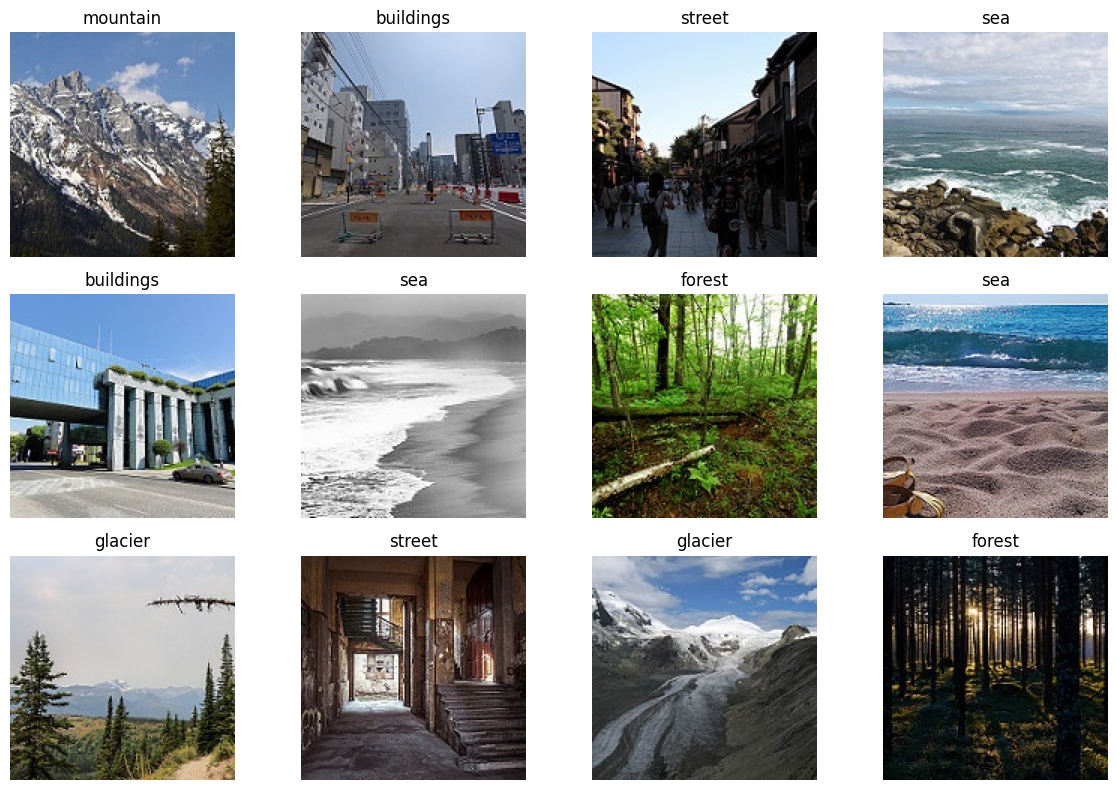

In [14]:
import random
from PIL import Image
import matplotlib.pyplot as plt

random_indices = random.sample(range(len(image_paths)), 12)

plt.figure(figsize=(12, 8))

for i, idx in enumerate(random_indices):

    img = Image.open(image_paths[idx])

    plt.subplot(3, 4, i + 1)

    plt.imshow(img)

    plt.title(CLASS_NAMES[labels[idx]])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
from collections import Counter

print(Counter(labels))

Counter({0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000})


In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(

    image_paths,
    labels,

    test_size=0.30,

    stratify=labels,

    random_state=42
)

In [18]:
X_val, X_test, y_val, y_test = train_test_split(

    X_temp,
    y_temp,

    test_size=0.50,

    stratify=y_temp,

    random_state=42
)

In [19]:
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 4200
Validation: 900
Test: 900


In [20]:
print("\nTRAIN")
print(Counter(y_train))

print("\nVALIDATION")
print(Counter(y_val))

print("\nTEST")
print(Counter(y_test))


TRAIN
Counter({4: 700, 2: 700, 3: 700, 0: 700, 5: 700, 1: 700})

VALIDATION
Counter({0: 150, 5: 150, 2: 150, 1: 150, 4: 150, 3: 150})

TEST
Counter({5: 150, 0: 150, 2: 150, 4: 150, 1: 150, 3: 150})


In [21]:
FINAL_DATASET_DIR = "/content/intel_final_dataset"

# Agar pehle se folder exist karta hai to remove karo
if os.path.exists(FINAL_DATASET_DIR):
    shutil.rmtree(FINAL_DATASET_DIR)

# Folders create karo
for split in ["train", "val", "test"]:

    for class_name in CLASS_NAMES:

        os.makedirs(
            os.path.join(
                FINAL_DATASET_DIR,
                split,
                class_name
            ),
            exist_ok=True
        )

print("Train/Val/Test folders created!")

Train/Val/Test folders created!


In [22]:
def copy_images(
    paths,
    labels,
    split_name
):

    for path, label in zip(paths, labels):

        class_name = CLASS_NAMES[label]

        destination = os.path.join(
            FINAL_DATASET_DIR,
            split_name,
            class_name
        )

        shutil.copy2(
            path,
            destination
        )

    print(
        split_name,
        "completed:",
        len(paths),
        "images"
    )

In [24]:
copy_images(
    X_train,
    y_train,
    "train"
)

copy_images(
    X_val,
    y_val,
    "val"
)

copy_images(
    X_test,
    y_test,
    "test"
)

train completed: 4200 images
val completed: 900 images
test completed: 900 images


In [25]:
for split in ["train", "val", "test"]:

    print("\n", split.upper())

    total = 0

    for class_name in CLASS_NAMES:

        folder = os.path.join(
            FINAL_DATASET_DIR,
            split,
            class_name
        )

        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ])

        print(
            class_name,
            ":",
            count
        )

        total += count

    print("Total:", total)


 TRAIN
buildings : 700
forest : 700
glacier : 700
mountain : 700
sea : 700
street : 700
Total: 4200

 VAL
buildings : 150
forest : 150
glacier : 150
mountain : 150
sea : 150
street : 150
Total: 900

 TEST
buildings : 150
forest : 150
glacier : 150
mountain : 150
sea : 150
street : 150
Total: 900


In [26]:
TRAIN_DIR = "/content/intel_final_dataset/train"
VAL_DIR = "/content/intel_final_dataset/val"
TEST_DIR = "/content/intel_final_dataset/test"

print(TRAIN_DIR)
print(VAL_DIR)
print(TEST_DIR)

/content/intel_final_dataset/train
/content/intel_final_dataset/val
/content/intel_final_dataset/test


In [30]:
IMG_SIZE_ML = 64

In [27]:
def load_images_for_ml(
    directory,
    img_size=64
):

    X = []
    y = []

    for class_index, class_name in enumerate(CLASS_NAMES):

        class_path = os.path.join(
            directory,
            class_name
        )

        files = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ]

        print(
            class_name,
            ":",
            len(files)
        )

        for filename in files:

            image_path = os.path.join(
                class_path,
                filename
            )

            image = Image.open(
                image_path
            ).convert("RGB")

            image = image.resize(
                (img_size, img_size)
            )

            image = np.array(
                image,
                dtype=np.float32
            )
            image = image / 255.0

            image = image.reshape(-1)

            X.append(image)
            y.append(class_index)

    return (
        np.array(X),
        np.array(y)
    )

In [28]:
X_train_ml, y_train_ml = load_images_for_ml(
    TRAIN_DIR
)

X_val_ml, y_val_ml = load_images_for_ml(
    VAL_DIR
)

X_test_ml, y_test_ml = load_images_for_ml(
    TEST_DIR
)

buildings : 700
forest : 700
glacier : 700
mountain : 700
sea : 700
street : 700
buildings : 150
forest : 150
glacier : 150
mountain : 150
sea : 150
street : 150
buildings : 150
forest : 150
glacier : 150
mountain : 150
sea : 150
street : 150


In [29]:
print(
    "Train:",
    X_train_ml.shape,
    y_train_ml.shape
)

print(
    "Validation:",
    X_val_ml.shape,
    y_val_ml.shape
)

print(
    "Test:",
    X_test_ml.shape,
    y_test_ml.shape
)

Train: (4200, 12288) (4200,)
Validation: (900, 12288) (900,)
Test: (900, 12288) (900,)


In [30]:
svm_model = SVC(
    kernel="linear",
    C=1.0
)

print("Training SVM...")

svm_model.fit(
    X_train_ml,
    y_train_ml
)

print("SVM training completed!")

Training SVM...
SVM training completed!


In [31]:
svm_val_pred = svm_model.predict(
    X_val_ml
)

svm_val_acc = accuracy_score(
    y_val_ml,
    svm_val_pred
)

print(
    "SVM Validation Accuracy:",
    svm_val_acc
)

SVM Validation Accuracy: 0.4488888888888889


In [32]:
svm_test_pred = svm_model.predict(
    X_test_ml
)

svm_test_acc = accuracy_score(
    y_test_ml,
    svm_test_pred
)

print(
    "SVM Test Accuracy:",
    svm_test_acc
)

SVM Test Accuracy: 0.49777777777777776


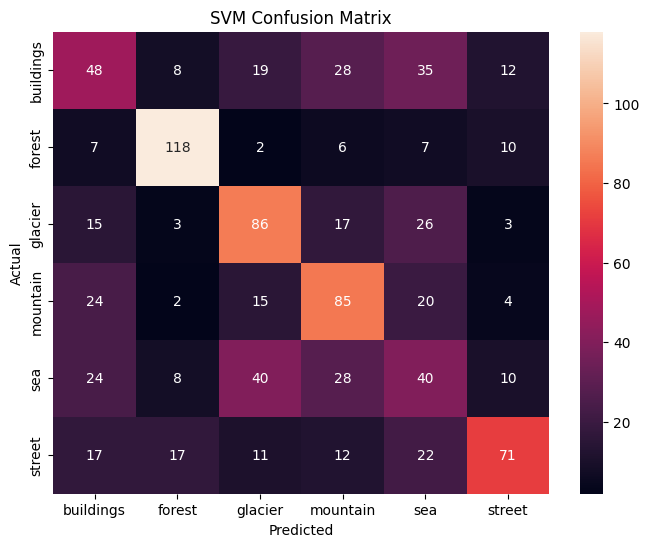

In [34]:
cm = confusion_matrix(
    y_test_ml,
    svm_test_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")

plt.show()

In [35]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

print("Training KNN...")

knn_model.fit(
    X_train_ml,
    y_train_ml
)

print("KNN training completed!")

Training KNN...
KNN training completed!


In [36]:
knn_val_pred = knn_model.predict(
    X_val_ml
)

knn_val_acc = accuracy_score(
    y_val_ml,
    knn_val_pred
)

print(
    "KNN Validation Accuracy:",
    knn_val_acc
)

KNN Validation Accuracy: 0.4255555555555556


In [37]:
knn_test_pred = knn_model.predict(
    X_test_ml
)

knn_test_acc = accuracy_score(
    y_test_ml,
    knn_test_pred
)

print(
    "KNN Test Accuracy:",
    knn_test_acc
)

KNN Test Accuracy: 0.4288888888888889


In [38]:
ann_model = models.Sequential([

    layers.Input(
        shape=(X_train_ml.shape[1],)
    ),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.3),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,179,654 (12.13 MB)

 Trainable params: 3,179,654 (12.13 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
ann_model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [43]:
history_ann = ann_model.fit(

    X_train_ml,
    y_train_ml,

    validation_data=(
        X_val_ml,
        y_val_ml
    ),

    epochs=88,

    batch_size=32
)

Epoch 1/88
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2743 - loss: 1.5946 - val_accuracy: 0.1856 - val_loss: 1.7802
Epoch 2/88
132/132 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.2536 - loss: 1.6373 - val_accuracy: 0.2644 - val_loss: 1.6054
Epoch 3/88
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2917 - loss: 1.5606 - val_accuracy: 0.2767 - val_loss: 1.6324
Epoch 4/88
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2898 - loss: 1.5600 - val_accuracy: 0.2711 - val_loss: 1.6032
Epoch 5/88
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3007 - loss: 1.5479 - val_accuracy: 0.3111 - val_loss: 1.6472
Epoch 6/88
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3012 - loss: 1.5425 - val_accuracy: 0.2933 - val_loss: 1.6289
Epoch 7/88
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2993 - loss: 1.5589 - val_accuracy: 0.2689 - val_loss: 1.7492
Epoch 8/88
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2950 - loss: 1.5651 - val_accuracy: 0

In [45]:
ann_test_loss, ann_test_acc = ann_model.evaluate(

    X_test_ml,
    y_test_ml,

    verbose=0
)

print(
    "ANN Test Accuracy:",
    ann_test_acc
)

ANN Test Accuracy: 0.3166666626930237


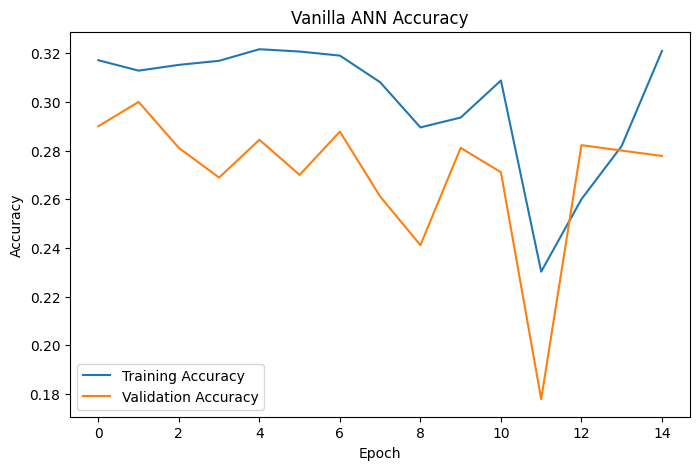

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_ann.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_ann.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Vanilla ANN Accuracy")
plt.legend()

plt.show()

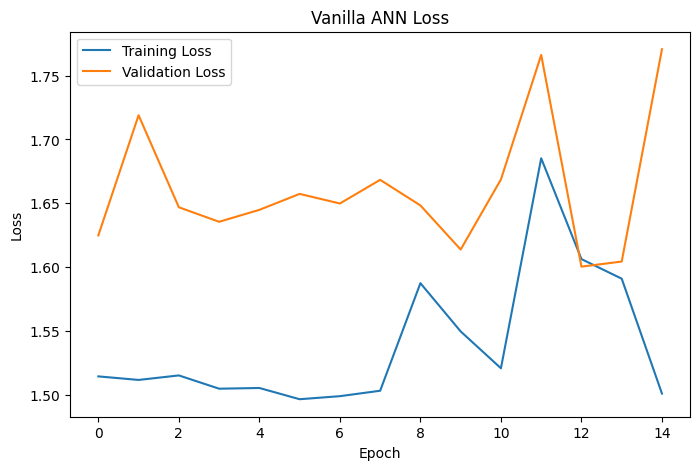

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_ann.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_ann.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Vanilla ANN Loss")
plt.legend()

plt.show()

In [48]:
IMG_SIZE_CNN = (128, 128)
BATCH_SIZE = 32

In [49]:
train_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    image_size=IMG_SIZE_CNN,

    batch_size=BATCH_SIZE,

    label_mode="int",

    shuffle=True,

    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(

    VAL_DIR,

    image_size=IMG_SIZE_CNN,

    batch_size=BATCH_SIZE,

    label_mode="int",

    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    image_size=IMG_SIZE_CNN,

    batch_size=BATCH_SIZE,

    label_mode="int",

    shuffle=False
)

Found 4200 files belonging to 6 classes.
Found 900 files belonging to 6 classes.
Found 900 files belonging to 6 classes.


In [50]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    AUTOTUNE
)

val_ds = val_ds.prefetch(
    AUTOTUNE
)

test_ds = test_ds.prefetch(
    AUTOTUNE
)

In [51]:
custom_cnn = models.Sequential([

    layers.Input(
        shape=(128, 128, 3)
    ),

    layers.Rescaling(
        1./255
    ),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Flatten(),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

custom_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,483,654 (32.36 MB)

 Trainable params: 8,483,654 (32.36 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
custom_cnn.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [53]:
history_cnn = custom_cnn.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15
)

Epoch 1/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 13s 60ms/step - accuracy: 0.5019 - loss: 1.2605 - val_accuracy: 0.6578 - val_loss: 0.9497
Epoch 2/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.6276 - loss: 0.9687 - val_accuracy: 0.6800 - val_loss: 0.8200
Epoch 3/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - accuracy: 0.6902 - loss: 0.8132 - val_accuracy: 0.6967 - val_loss: 0.7710
Epoch 4/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.7379 - loss: 0.7036 - val_accuracy: 0.7556 - val_loss: 0.6640
Epoch 5/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7852 - loss: 0.5851 - val_accuracy: 0.7444 - val_loss: 0.7188
Epoch 6/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.8317 - loss: 0.4642 - val_accuracy: 0.7767 - val_loss: 0.6580
Epoch 7/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.8752 - loss: 0.3482 - val_accuracy: 0.7300 - val_loss: 0.8985
Epoch 8/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 0.9005 - loss: 0.2976 - val_acc

In [54]:
cnn_test_loss, cnn_test_acc = custom_cnn.evaluate(
    test_ds,
    verbose=1
)

print(
    "Custom CNN Test Accuracy:",
    cnn_test_acc
)

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7889 - loss: 1.0628
Custom CNN Test Accuracy: 0.7888888716697693


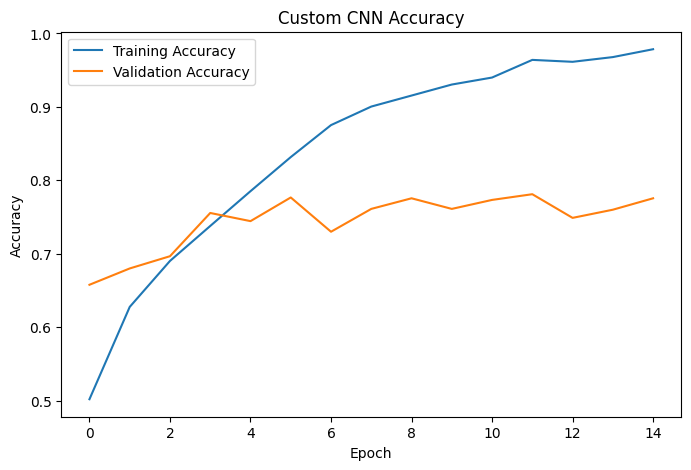

In [55]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_cnn.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Custom CNN Accuracy")
plt.legend()

plt.show()

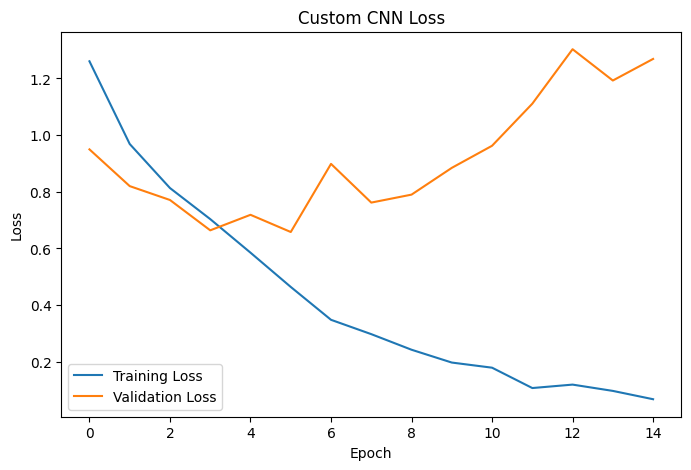

In [56]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN Loss")
plt.legend()

plt.show()

In [57]:
data_augmentation = tf.keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.1
    ),

    layers.RandomZoom(
        0.1
    )
])

In [58]:
aug_cnn = models.Sequential([

    layers.Input(
        shape=(128, 128, 3)
    ),

    data_augmentation,

    layers.Rescaling(
        1./255
    ),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Flatten(),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

aug_cnn.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,483,654 (32.36 MB)

 Trainable params: 8,483,654 (32.36 MB)

 Non-trainable params: 0 (0.00 B)

In [59]:
aug_cnn.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [60]:
history_aug = aug_cnn.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15
)


aug_test_loss, aug_test_acc = aug_cnn.evaluate(
    test_ds,
    verbose=1
)

print(
    "CNN + Augmentation Test Accuracy:",
    aug_test_acc
)

Epoch 1/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.4771 - loss: 1.3151 - val_accuracy: 0.6389 - val_loss: 0.9343
Epoch 2/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.5864 - loss: 1.0784 - val_accuracy: 0.6622 - val_loss: 0.9062
Epoch 3/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.6286 - loss: 0.9930 - val_accuracy: 0.7033 - val_loss: 0.7760
Epoch 4/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.6479 - loss: 0.9420 - val_accuracy: 0.7100 - val_loss: 0.7409
Epoch 5/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.6810 - loss: 0.8511 - val_accuracy: 0.7167 - val_loss: 0.7176
Epoch 6/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.6867 - loss: 0.8398 - val_accuracy: 0.7278 - val_loss: 0.7123
Epoch 7/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.7100 - loss: 0.7947 - val_accuracy: 0.7378 - val_loss: 0.6549
Epoch 8/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.7307 - loss: 0.7439 - val_accu

In [64]:
IMG_SIZE_RESNET = (224, 224)
BATCH_SIZE_RESNET = 32


resnet_train_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    image_size=IMG_SIZE_RESNET,

    batch_size=BATCH_SIZE_RESNET,

    label_mode="int",

    shuffle=True,

    seed=42
)

resnet_val_ds = tf.keras.utils.image_dataset_from_directory(

    VAL_DIR,

    image_size=IMG_SIZE_RESNET,

    batch_size=BATCH_SIZE_RESNET,

    label_mode="int",

    shuffle=False
)

resnet_test_ds = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    image_size=IMG_SIZE_RESNET,

    batch_size=BATCH_SIZE_RESNET,

    label_mode="int",

    shuffle=False
)
base_model = ResNet50(

    weights="imagenet",

    include_top=False,

    input_shape=(224, 224, 3)
)

base_model.trainable = False


resnet_model = models.Sequential([

    layers.Input(
        shape=(224, 224, 3)
    ),

    layers.Lambda(
        preprocess_input
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

resnet_model.summary()

Found 4200 files belonging to 6 classes.
Found 900 files belonging to 6 classes.
Found 900 files belonging to 6 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,798 (91.99 MB)

 Trainable params: 526,086 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [65]:
resnet_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [66]:
resnet_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)


history_resnet = resnet_model.fit(

    resnet_train_ds,

    validation_data=resnet_val_ds,

    epochs=10
)

resnet_test_loss, resnet_test_acc = resnet_model.evaluate(

    resnet_test_ds,

    verbose=1
)

print(
    "ResNet50 Test Accuracy:",
    resnet_test_acc
)

Epoch 1/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 41s 202ms/step - accuracy: 0.7317 - loss: 0.7675 - val_accuracy: 0.8911 - val_loss: 0.2833
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 13s 97ms/step - accuracy: 0.8917 - loss: 0.3136 - val_accuracy: 0.9089 - val_loss: 0.2287
Epoch 3/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - accuracy: 0.9083 - loss: 0.2622 - val_accuracy: 0.9156 - val_loss: 0.2084
Epoch 4/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 13s 97ms/step - accuracy: 0.9238 - loss: 0.2212 - val_accuracy: 0.9200 - val_loss: 0.2036
Epoch 5/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 13s 99ms/step - accuracy: 0.9302 - loss: 0.2019 - val_accuracy: 0.9278 - val_loss: 0.1943
Epoch 6/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 13s 100ms/step - accuracy: 0.9321 - loss: 0.1829 - val_accuracy: 0.9300 - val_loss: 0.1939
Epoch 7/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 13s 99ms/step - accuracy: 0.9429 - loss: 0.1629 - val_accuracy: 0.9267 - val_loss: 0.1916
Epoch 8/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step - accuracy: 0.9467 - loss: 0.149

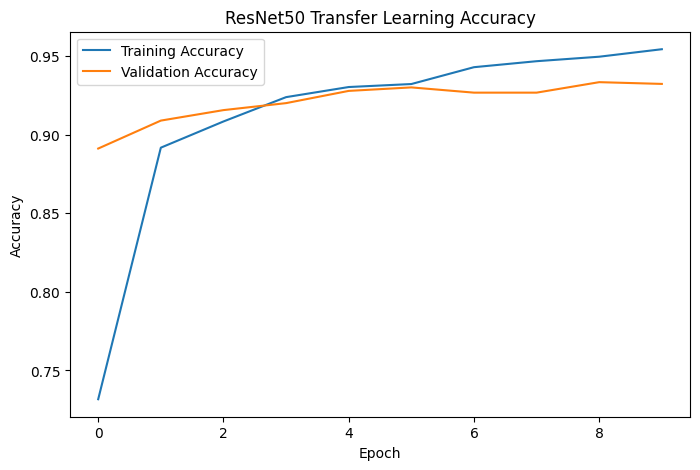

In [67]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_resnet.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_resnet.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "ResNet50 Transfer Learning Accuracy"
)

plt.legend()

plt.show()

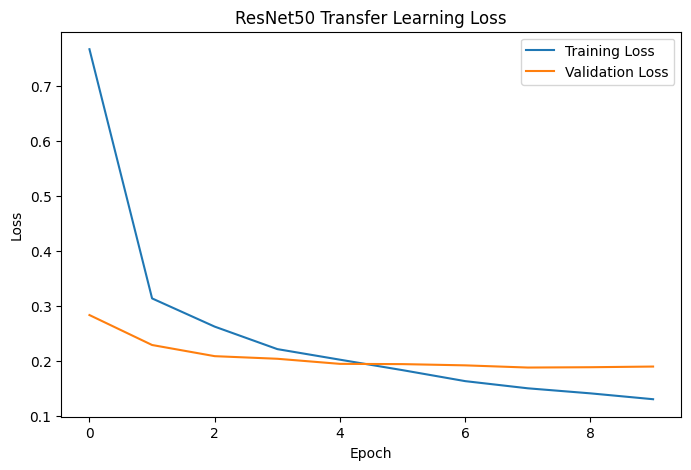

In [68]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_resnet.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_resnet.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet50 Transfer Learning Loss"
)

plt.legend()

plt.show()

In [69]:
resnet_predictions = resnet_model.predict(
    resnet_test_ds
)

resnet_pred_labels = np.argmax(
    resnet_predictions,
    axis=1
)

29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 199ms/step


In [70]:
resnet_true_labels = np.concatenate([

    y.numpy()

    for x, y in resnet_test_ds

])

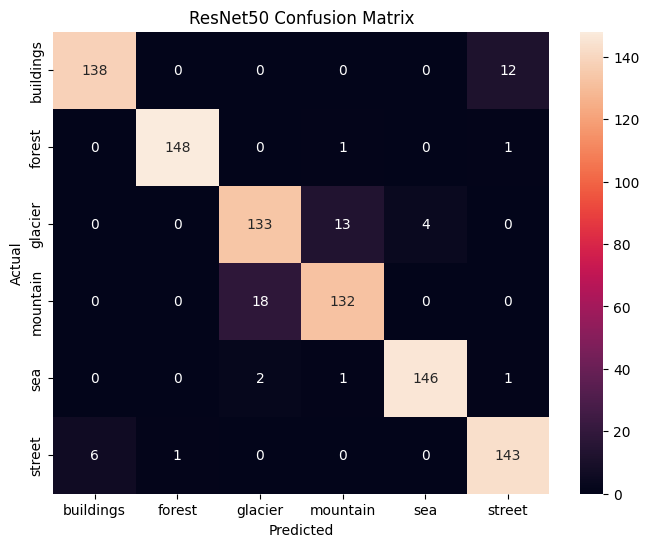

In [71]:
cm = confusion_matrix(

    resnet_true_labels,

    resnet_pred_labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "ResNet50 Confusion Matrix"
)

plt.show()

In [72]:
print(
    classification_report(

        resnet_true_labels,

        resnet_pred_labels,

        target_names=CLASS_NAMES
    )
)

              precision    recall  f1-score   support

   buildings       0.96      0.92      0.94       150
      forest       0.99      0.99      0.99       150
     glacier       0.87      0.89      0.88       150
    mountain       0.90      0.88      0.89       150
         sea       0.97      0.97      0.97       150
      street       0.91      0.95      0.93       150

    accuracy                           0.93       900
   macro avg       0.93      0.93      0.93       900
weighted avg       0.93      0.93      0.93       900



In [73]:
results = pd.DataFrame({

    "Model": [

        "SVM",

        "KNN",

        "Vanilla ANN",

        "Custom CNN",

        "CNN + Augmentation",

        "ResNet50 Transfer Learning"

    ],

    "Test Accuracy": [

        svm_test_acc,

        knn_test_acc,

        ann_test_acc,

        cnn_test_acc,

        aug_test_acc,

        resnet_test_acc

    ]

})

results["Test Accuracy (%)"] = (
    results["Test Accuracy"] * 100
)

results

,Model,Test Accuracy,Test Accuracy (%)
0,SVM,0.497778,49.777778
1,KNN,0.428889,42.888889
2,Vanilla ANN,0.316667,31.666666
3,Custom CNN,0.788889,78.888887
4,CNN + Augmentation,0.811111,81.111109
5,ResNet50 Transfer Learning,0.933333,93.333334


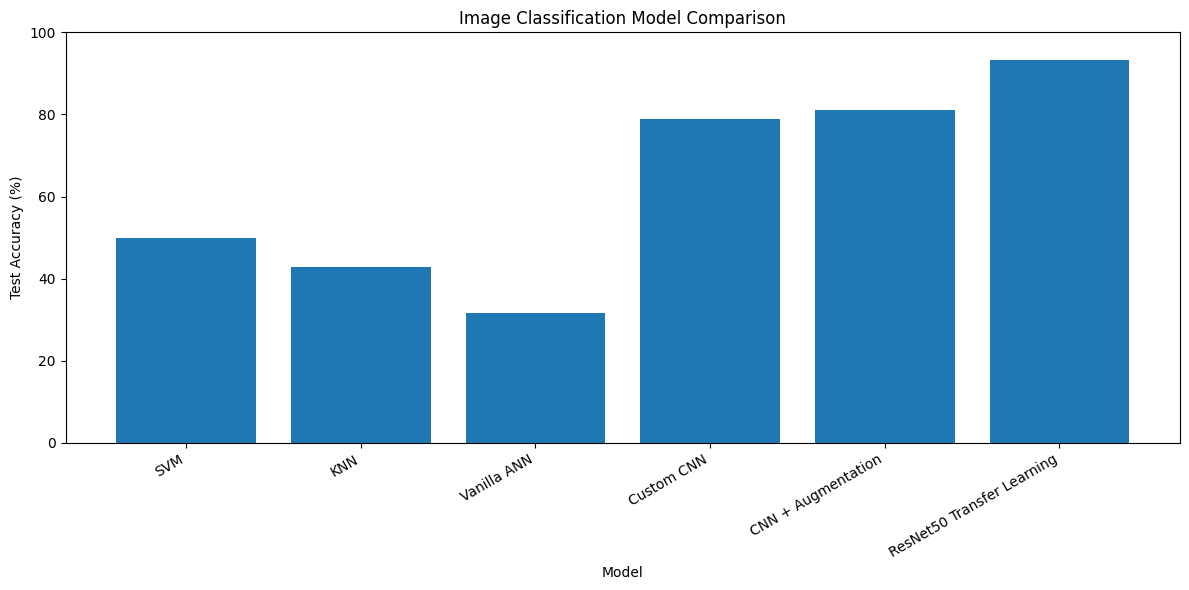

In [74]:
plt.figure(figsize=(12, 6))

plt.bar(

    results["Model"],

    results["Test Accuracy (%)"]

)

plt.xlabel("Model")

plt.ylabel("Test Accuracy (%)")

plt.title(
    "Image Classification Model Comparison"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylim(0, 100)

plt.tight_layout()

plt.show()